# Modul 6: CNN Lanjutan dan Transfer Learning

**Nama:** Ahmad Farhan Ghani  
**NIM:** 123450121  
**Kelas:** RA
**Tanggal:** 2026-10-28
**Sumber dataset:** data transfer 4 kelas turunan Fashion-MNIST

Simpan berkas ini sebagai `M06_NIM.ipynb` sebelum mulai mengerjakan.

## Petunjuk

Notebook ini memiliki tiga jenis bagian. Tanda di akhir judul menunjukkan jenisnya.

| Tanda | Bagian | Yang Anda lakukan |
|:---|:---|:---|
| **Terbimbing** | Pre-lab, B–F | Jawaban lengkap Prosedur Praktikum Terbimbing sudah tersedia. Jalankan, baca kodenya, lalu cocokkan keluarannya dengan tab **Materi** modul. |
| **Latihan Mandiri di Lab** | Latihan | Dikerjakan sendiri di laboratorium setelah bagian terbimbing. |
| **Tugas Individu** | G–H | Dikerjakan di luar sesi dan dikumpulkan lewat Tugas. |

1. Isi identitas di atas dan `NIM` pada sel pertama. Hanya itu isian pada bagian terbimbing.
2. Siapkan data lebih dahulu dengan menekan **Siapkan dataset di laptop** di halaman modul. Data transfer 4 kelas × 120 citra masuk ke `data/raw/transfer/` dan bobot `ResNet18_Weights.IMAGENET1K_V1` ke `data/raw/torch/`. Tidak ada sel yang mengunduh data atau bobot.
3. Tekan **Restart**, lalu **Run all**. Seluruh sel terbimbing berjalan di kernel Deep Learning (PyTorch CPU) dan berhenti di sel Latihan pertama yang masih berisi `TODO`. Bagian E dan F melatih lima model ResNet18 di CPU sehingga memerlukan waktu beberapa menit per run; log epoch tampil bertahap.
4. Keluaran yang tidak bergantung pada NIM, yaitu isi transformasi, ukuran split, jumlah parameter, dan bukti pembekuan, harus sama persis dengan naskah. Angka hasil training bergantung pada seed NIM Anda.
5. Pada bagian Latihan dan Tugas, ganti seluruh penanda `TODO`. Transformasi tetap berasal dari `weights.transforms()`, augmentasi hanya melekat pada split latih, dan test set dipakai **satu kali** pada bagian G.
6. Sebelum mengumpulkan, jalankan **Restart** lalu **Run all** sampai seluruh sel selesai tanpa galat. Pertahankan semua hasil eksperimen, termasuk yang tidak sesuai hipotesis.

In [2]:
import copy
import platform
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
from torchvision.models import ResNet18_Weights, resnet18

# Kernel Workbench menangkap figure di akhir setiap sel; plt.show() dipertahankan
# agar notebook tetap berjalan di Jupyter biasa, tanpa peringatan backend Agg.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

NIM = '123450121'  # Ganti dengan NIM lengkap Anda, misalnya '120140167'.
assert NIM.isdigit() and len(NIM) >= 4, 'Isi NIM dengan angka sebelum melanjutkan.'
SEED = int(NIM[-4:])  # seed individual: empat digit terakhir NIM
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
pd.set_option('display.precision', 4)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
environment = {
    'python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'torch': torch.__version__,
    'device': str(DEVICE),
    'seed': SEED,
}
environment

{'python': '3.12.10', 'numpy': '2.5.3', 'pandas': '3.0.5', 'torch': '2.14.0+cpu', 'device': 'cpu', 'seed': 121}

## A. Pre-lab · Terbimbing

1. **Mengapa normalisasi harus sama dengan saat pralatih:** Bobot awal belajar dari masukan pada skala/distribusi kanal tertentu. Mengubah normalisasi menggeser distribusi aktivasi sejak layer pertama sehingga fitur pralatih dan statistik BatchNorm tidak lagi menerima data seperti yang diharapkan.
2. **Gradien dan waktu komputasi layer beku:** Parameter dengan `requires_grad=False` tidak memperoleh tensor `.grad` dan autograd tidak menghitung turunan terhadap parameter itu. Forward pass tetap dilakukan, tetapi penyimpanan aktivasi/backward untuk bagian beku berkurang sehingga memori dan waktu training biasanya lebih kecil.
3. **Parameter `Linear(512,5)`:** $512\times5+5=2\,565$ parameter, terdiri atas 2.560 bobot dan 5 bias.
4. **Mengapa LR fine-tuning lebih kecil:** Bobot pralatih sudah berada pada representasi yang berguna; langkah besar dapat merusaknya (*catastrophic forgetting*). Learning rate kecil menyesuaikan fitur secara bertahap, sedangkan model acak perlu bergerak lebih jauh dari inisialisasinya.

## B. Bobot pralatih dan praproses · Terbimbing

Ambil transformasi dari objek bobot, lalu bangun augmentasi yang memakai normalisasi **yang sama**.

In [3]:
bobot = ResNet18_Weights.IMAGENET1K_V1
tf_eval = bobot.transforms()
print(tf_eval)
MEAN = tuple(tf_eval.mean)
STD = tuple(tf_eval.std)
SISI = int(tf_eval.crop_size[0])

tf_aug = T.Compose([
    T.RandomResizedCrop(SISI, scale=(0.8, 1.0)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD),
])

print('crop:', SISI, '| mean:', MEAN, '| std:', STD)
assert list(MEAN) == [0.485, 0.456, 0.406], 'MEAN harus berasal dari bobot pralatih'
assert list(STD) == [0.229, 0.224, 0.225]

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
crop: 224 | mean: (0.485, 0.456, 0.406) | std: (0.229, 0.224, 0.225)


In [4]:
ROOT = Path('../../data/raw/transfer')
if not ROOT.exists():
    ROOT = Path('data/raw/transfer')

ds_aug = ImageFolder(ROOT, transform=tf_aug)
ds_polos = ImageFolder(ROOT, transform=tf_eval)
KELAS = ds_polos.classes
y = np.array(ds_polos.targets)
all_indices = np.arange(len(y))

idx_latih, idx_sisa = train_test_split(
    all_indices,
    test_size=0.30,
    stratify=y,
    random_state=SEED,
)
idx_val, idx_uji = train_test_split(
    idx_sisa,
    test_size=0.50,
    stratify=y[idx_sisa],
    random_state=SEED,
)

ds_latih = Subset(ds_aug, idx_latih)
# Versi polos hanya untuk menghitung metrik train yang sebanding dengan validation.
ds_latih_polos = Subset(ds_polos, idx_latih)
ds_val = Subset(ds_polos, idx_val)
ds_uji = Subset(ds_polos, idx_uji)

print(f'kelas ({len(KELAS)}): {KELAS}')
print(f'latih {len(ds_latih)}  validasi {len(ds_val)}  uji {len(ds_uji)}')
print('citra per kelas:', np.bincount(y).tolist())
print('distribusi train/val/test:',
      np.bincount(y[idx_latih]).tolist(),
      np.bincount(y[idx_val]).tolist(),
      np.bincount(y[idx_uji]).tolist())

assert len(KELAS) >= 4, 'dataset harus punya minimal empat kelas'
assert np.bincount(y).min() >= 120, 'setiap kelas minimal 120 citra'
assert (len(ds_latih), len(ds_val), len(ds_uji)) == (336, 72, 72)
assert ds_val.dataset is ds_polos and ds_uji.dataset is ds_polos
assert ds_latih.dataset is ds_aug
print('dataset dan split sesuai protokol')

kelas (4): ['coat', 'pullover', 'shirt', 't_shirt_top']
latih 336  validasi 72  uji 72
citra per kelas: [120, 120, 120, 120]
distribusi train/val/test: [84, 84, 84, 84] [18, 18, 18, 18] [18, 18, 18, 18]
dataset dan split sesuai protokol


shape batch  : (8, 3, 224, 224) torch.float32
rentang nilai: -2.118 s.d. 2.640 (sesudah Normalize)
label        : ['coat', 't_shirt_top', 'shirt', 'shirt', 'coat', 'pullover', 't_shirt_top', 'pullover']


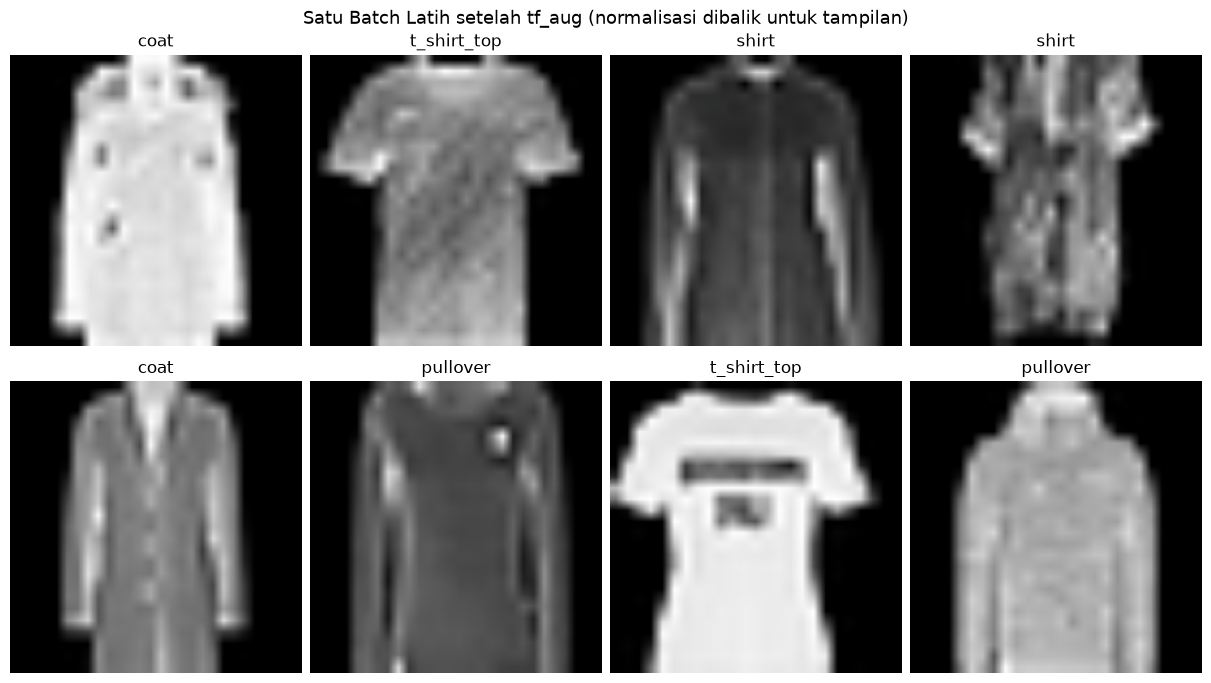

In [5]:
# Satu batch latih persis seperti yang akan dilihat model (sudah melalui tf_aug).
g_contoh = torch.Generator().manual_seed(SEED)
xb_contoh, yb_contoh = next(iter(DataLoader(ds_latih, batch_size=8, shuffle=True, generator=g_contoh)))
print('shape batch  :', tuple(xb_contoh.shape), xb_contoh.dtype)
print(f'rentang nilai: {xb_contoh.min().item():.3f} s.d. {xb_contoh.max().item():.3f} (sesudah Normalize)')
print('label        :', [KELAS[i] for i in yb_contoh.tolist()])

# Normalize dibalik hanya untuk ditampilkan: x * std + mean.
mean_tensor = torch.tensor(MEAN).view(3, 1, 1)
std_tensor = torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 4, figsize=(12, 6.8), constrained_layout=True)
for ax, image, label in zip(axes.flat, xb_contoh, yb_contoh):
    ax.imshow((image * std_tensor + mean_tensor).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(KELAS[int(label)])
    ax.axis('off')
fig.suptitle('Satu Batch Latih setelah tf_aug (normalisasi dibalik untuk tampilan)', fontsize=13)
plt.show()

## C. Head baru dan hitungan parameter · Terbimbing

In [6]:
K = len(KELAS)

def buat_model(pralatih=True):
    seed_everything(SEED)
    weights = bobot if pralatih else None
    model = resnet18(weights=weights)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, K)
    return model.to(DEVICE)

model = buat_model()
total = sum(parameter.numel() for parameter in model.parameters())
head = sum(parameter.numel() for parameter in model.fc.parameters())
layer4 = sum(parameter.numel() for parameter in model.layer4.parameters())

print(f'total          : {total:,}')
print(f'head           : {head:,}  ({100*head/total:.3f}%)')
print(f'layer4 + head  : {layer4 + head:,}  ({100*(layer4+head)/total:.1f}%)')
assert head == 512 * K + K, 'dimensi head belum sesuai jumlah kelas'

total          : 11,178,564
head           : 2,052  (0.018%)
layer4 + head  : 8,395,780  (75.1%)


## D. Membekukan dan membuktikannya · Terbimbing

Dua bukti wajib: status `requires_grad`, **dan** bobot beku yang tidak bergerak setelah satu update.

In [7]:
def bekukan(model, strategi):
    strategi = strategi.strip().lower()
    if strategi not in {'frozen', 'partial', 'full', 'scratch'}:
        raise ValueError("strategi harus 'frozen', 'partial', 'full', atau 'scratch'")

    for parameter in model.parameters():
        parameter.requires_grad = False

    if strategi == 'frozen':
        for parameter in model.fc.parameters():
            parameter.requires_grad = True
    elif strategi == 'partial':
        for parameter in model.layer4.parameters():
            parameter.requires_grad = True
        for parameter in model.fc.parameters():
            parameter.requires_grad = True
    else:  # full dan scratch
        for parameter in model.parameters():
            parameter.requires_grad = True
    return model

def n_terlatih(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

trainable_by_strategy = {}
for strategi in ('frozen', 'partial', 'full'):
    current = bekukan(buat_model(), strategi)
    trainable_by_strategy[strategi] = n_terlatih(current)
    print(f'{strategi:>8}: {n_terlatih(current):>11,} ({100*n_terlatih(current)/total:5.1f}%)')

m_cek = bekukan(buat_model(), 'frozen')
assert n_terlatih(m_cek) == head, 'strategi frozen harus melatih head saja'
assert all(not parameter.requires_grad for parameter in m_cek.layer1.parameters())
assert all(parameter.requires_grad for parameter in m_cek.fc.parameters())

  frozen:       2,052 (  0.0%)
 partial:   8,395,780 ( 75.1%)
    full:  11,178,564 (100.0%)


In [8]:
salinan = m_cek.layer1[0].conv1.weight.detach().clone()
head_before = m_cek.fc.weight.detach().clone()
optimizer_check = torch.optim.Adam(
    [parameter for parameter in m_cek.parameters() if parameter.requires_grad],
    lr=1e-3,
)
criterion_check = nn.CrossEntropyLoss()
check_loader = DataLoader(ds_latih, batch_size=8, shuffle=False)
xb_check, yb_check = next(iter(check_loader))
xb_check, yb_check = xb_check.to(DEVICE), yb_check.to(DEVICE)

m_cek.eval()  # Backbone dan BatchNorm tetap; head Linear tetap dapat belajar.
optimizer_check.zero_grad()
loss_check = criterion_check(m_cek(xb_check), yb_check)
loss_check.backward()
optimizer_check.step()

selisih = (m_cek.layer1[0].conv1.weight.detach() - salinan).abs().max().item()
head_change = (m_cek.fc.weight.detach() - head_before).abs().max().item()
print(f'selisih maksimum bobot beku: {selisih:.2e}')
print(f'perubahan maksimum head     : {head_change:.2e}')
assert selisih == 0.0, 'bobot beku ternyata berubah — periksa isi optimizer'
assert head_change > 0.0, 'head seharusnya berubah setelah update'
print('pembekuan terbukti dengan status gradien dan update nyata')

selisih maksimum bobot beku: 0.00e+00
perubahan maksimum head     : 1.00e-03
pembekuan terbukti dengan status gradien dan update nyata


In [9]:
# Strategi partial: hanya layer4 dan head yang boleh berubah setelah satu update.
m_partial = bekukan(buat_model(), 'partial')
sebelum = {nama: parameter.detach().clone() for nama, parameter in m_partial.named_parameters()}
optimizer_partial = torch.optim.Adam(
    [parameter for parameter in m_partial.parameters() if parameter.requires_grad],
    lr=1e-4,
)
m_partial.eval()           # BatchNorm blok beku memakai running statistics pralatih.
m_partial.layer4.train()
m_partial.fc.train()
optimizer_partial.zero_grad()
criterion_check(m_partial(xb_check), yb_check).backward()
optimizer_partial.step()

baris = []
for blok in ('conv1', 'bn1', 'layer1', 'layer2', 'layer3', 'layer4', 'fc'):
    anggota = [(nama, p) for nama, p in m_partial.named_parameters() if nama.split('.')[0] == blok]
    perubahan = max((p.detach() - sebelum[nama]).abs().max().item() for nama, p in anggota)
    baris.append({
        'blok': blok,
        'parameter': sum(p.numel() for _, p in anggota),
        'requires_grad': all(p.requires_grad for _, p in anggota),
        'perubahan_maks': perubahan,
    })
bukti_partial = pd.DataFrame(baris)
print(bukti_partial.to_string(index=False, formatters={
    'parameter': '{:,}'.format, 'perubahan_maks': '{:.2e}'.format}))

beku = bukti_partial[~bukti_partial['blok'].isin(['layer4', 'fc'])]
assert (beku['perubahan_maks'] == 0.0).all() and not beku['requires_grad'].any(), 'blok beku ternyata berubah'
assert (bukti_partial.set_index('blok').loc[['layer4', 'fc'], 'perubahan_maks'] > 0).all()
assert bukti_partial.loc[bukti_partial['blok'].isin(['layer4', 'fc']), 'parameter'].sum() == layer4 + head
print('pembekuan partial terbukti: hanya layer4 dan fc yang bergerak')

  blok parameter  requires_grad perubahan_maks
 conv1     9,408          False       0.00e+00
   bn1       128          False       0.00e+00
layer1   147,968          False       0.00e+00
layer2   525,568          False       0.00e+00
layer3 2,099,712          False       0.00e+00
layer4 8,393,728           True       1.00e-04
    fc     2,052           True       1.00e-04
pembekuan partial terbukti: hanya layer4 dan fc yang bergerak


### Mengapa dua bukti diperlukan?

`requires_grad=False` mencegah autograd membuat gradien baru, tetapi tidak otomatis menghapus gradien lama yang sudah tersimpan. Jika parameter dibekukan setelah pernah memperoleh `.grad` lalu tetap berada dalam optimizer—terutama optimizer yang memiliki momentum/weight decay—`step()` masih dapat mengubahnya memakai state/gradien lama. Bobot juga dapat berubah melalui operasi manual *in-place* atau pemuatan checkpoint; karena itu membandingkan salinan bobot sebelum/sesudah update membuktikan perilaku aktual, bukan hanya konfigurasi flag.

## E. Empat run terkendali · Terbimbing

Data, seed, batch, dan epoch sama. Yang berbeda hanya bobot awal dan bagian yang boleh berubah.

In [10]:
BATCH, EPOCH = 32, 5

def loader(ds, batch, acak):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch, shuffle=acak,
                      generator=generator if acak else None)

@torch.no_grad()
def evaluasi(model, ds):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss, correct = 0.0, 0
    for xb, yb in loader(ds, BATCH, False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += criterion(logits, yb).item()
        correct += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(ds), correct / len(ds)

def aktifkan_mode_training(model, strategi):
    model.train()
    if strategi == 'frozen':
        # Cegah running statistics BatchNorm backbone berubah.
        model.eval()
        model.fc.train()
    elif strategi == 'partial':
        model.eval()
        model.layer4.train()
        model.fc.train()

def jalankan(strategi, lr, label, epoch=EPOCH, augmentasi='ringan'):
    model = buat_model(pralatih=strategi != 'scratch')
    model = bekukan(model, strategi)
    trainable_parameters = [
        parameter for parameter in model.parameters() if parameter.requires_grad
    ]
    optimizer = torch.optim.Adam(trainable_parameters, lr=lr)
    criterion = nn.CrossEntropyLoss()
    train_loader = loader(ds_latih, BATCH, True)
    history = {
        'epoch': [], 'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': [], 'gap': [],
        'optimization_loss': [],
    }
    updates = 0
    start = time.perf_counter()

    for epoch_index in range(1, epoch + 1):
        aktifkan_mode_training(model, strategi)
        loss_sum, correct, seen = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(xb)
            correct += (logits.argmax(1) == yb).sum().item()
            seen += len(xb)
            updates += 1

        train_loss, train_acc = evaluasi(model, ds_latih_polos)
        val_loss, val_acc = evaluasi(model, ds_val)
        history['epoch'].append(epoch_index)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['gap'].append(val_loss - train_loss)
        history['optimization_loss'].append(loss_sum / seen)

    runtime = time.perf_counter() - start
    note = {
        'run_id': label,
        'seed': SEED,
        'strategi': strategi,
        'bobot_awal': 'random' if strategi == 'scratch' else 'ImageNet1K_V1',
        'learning_rate': lr,
        'parameter_total': sum(parameter.numel() for parameter in model.parameters()),
        'parameter_terlatih': n_terlatih(model),
        'augmentasi': augmentasi,
        'epochs': epoch,
        'n_update': updates,
        'train_loss': history['train_loss'][-1],
        'train_acc': history['train_acc'][-1],
        'val_loss': history['val_loss'][-1],
        'val_acc': history['val_acc'][-1],
        'gap': history['gap'][-1],
        'detik_per_epoch': runtime / epoch,
        'runtime_s': runtime,
        'status': 'ok',
    }
    return model, history, note

hasil, kurva, model_simpan = [], {}, {}
initial_runs = [
    ('scratch', 1e-3, 'from-scratch'),
    ('frozen', 1e-3, 'frozen-backbone'),
    ('partial', 1e-4, 'partial-layer4'),
    ('full', 1e-4, 'full-finetune'),
]
for strategi, lr, label in initial_runs:
    current_model, history, note = jalankan(strategi, lr, label)
    hasil.append(note)
    kurva[label] = history
    model_simpan[label] = current_model
    print(f"{label}: val_loss={note['val_loss']:.4f}, val_acc={note['val_acc']:.4f}, "
          f"trainable={note['parameter_terlatih']:,}, {note['detik_per_epoch']:.2f}s/epoch")

df_strategi = pd.DataFrame(hasil)
display(df_strategi[['run_id', 'bobot_awal', 'parameter_terlatih', 'n_update',
                      'val_loss', 'val_acc', 'gap', 'detik_per_epoch']])
assert len(hasil) == 4, 'harus ada empat run strategi'
assert set(df_strategi['n_update']) == {55}

from-scratch: val_loss=1.7132, val_acc=0.4167, trainable=11,178,564, 60.05s/epoch
frozen-backbone: val_loss=0.9025, val_acc=0.6944, trainable=2,052, 29.68s/epoch
partial-layer4: val_loss=0.6860, val_acc=0.7222, trainable=8,395,780, 41.55s/epoch
full-finetune: val_loss=0.6943, val_acc=0.7500, trainable=11,178,564, 57.39s/epoch


,run_id,bobot_awal,parameter_terlatih,n_update,val_loss,val_acc,gap,detik_per_epoch
0,from-scratch,random,11178564,55,1.7132,0.4167,0.4873,60.0503
1,frozen-backbone,ImageNet1K_V1,2052,55,0.9025,0.6944,0.1198,29.6823
2,partial-layer4,ImageNet1K_V1,8395780,55,0.6860,0.7222,0.5435,41.5472
3,full-finetune,ImageNet1K_V1,11178564,55,0.6943,0.7500,0.4461,57.3943


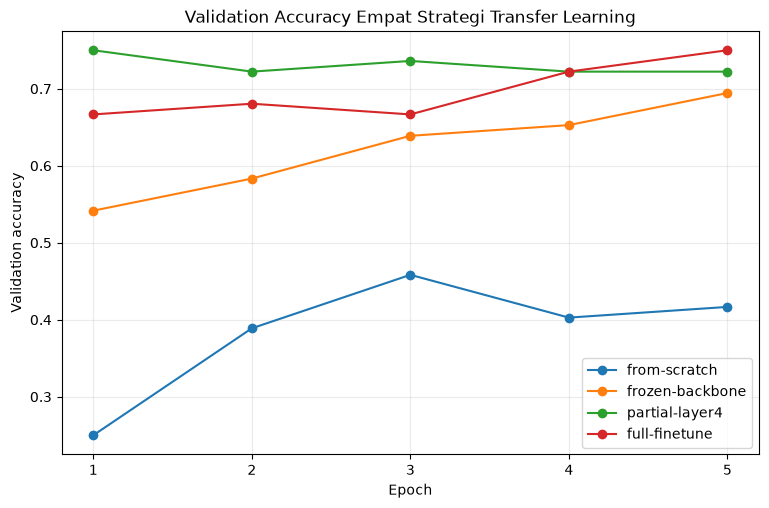

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for label, history in kurva.items():
    ax.plot(history['epoch'], history['val_acc'], marker='o', label=label)
ax.set(title='Validation Accuracy Empat Strategi Transfer Learning',
       xlabel='Epoch', ylabel='Validation accuracy')
ax.set_xticks(range(1, EPOCH + 1))
ax.grid(alpha=0.25)
ax.legend()
plt.show()

**Checkpoint menit ke-80.** Tunjukkan kepada asisten: parameter terlatih ketiga strategi, transformasi yang berasal dari objek bobot, dan selisih nol pada bobot beku.

## F. Augmentasi dan analisis kesalahan · Terbimbing

Augmentasi ringan (`RandomResizedCrop` skala 0,8–1,0 dan `RandomHorizontalFlip`) sudah dipakai keempat run bagian E. Strategi terbaik menurut validation loss dijalankan sekali lagi **tanpa augmentasi** dengan anggaran yang sama. Confusion matrix dan lima prediksi salah dihitung pada validation set; test set tetap untuk bagian G.

,run_id,augmentasi,train_loss,train_acc,val_loss,val_acc,gap
0,partial-layer4,ringan,0.1426,0.9851,0.686,0.7222,0.5435
1,partial-tanpa-augmentasi,tanpa,0.0238,1.0000,0.701,0.7500,0.6771


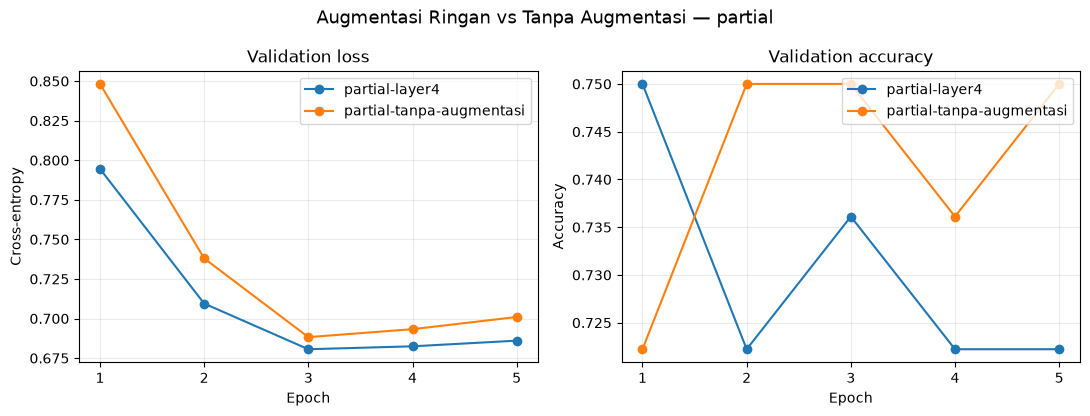

In [12]:
best_initial = df_strategi.sort_values('val_loss').iloc[0]
best_strategy = str(best_initial['strategi'])
best_lr = float(best_initial['learning_rate'])
label_tanpa = f'{best_strategy}-tanpa-augmentasi'

# Hanya split latih yang diubah: ds_latih menunjuk ds_aug, validasi dan uji tetap ds_polos.
try:
    ds_aug.transform = tf_eval
    current_model, history, note = jalankan(best_strategy, best_lr, label_tanpa, augmentasi='tanpa')
finally:
    ds_aug.transform = tf_aug
hasil.append(note)
kurva[label_tanpa] = history
model_simpan[label_tanpa] = current_model

tabel = pd.DataFrame(hasil)
perbandingan = tabel[tabel['strategi'] == best_strategy]
display(perbandingan[['run_id', 'augmentasi', 'train_loss', 'train_acc',
                      'val_loss', 'val_acc', 'gap']].reset_index(drop=True))
assert ds_aug.transform is tf_aug and len(tabel) == 5

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for run_id in perbandingan['run_id']:
    axes[0].plot(kurva[run_id]['epoch'], kurva[run_id]['val_loss'], marker='o', label=run_id)
    axes[1].plot(kurva[run_id]['epoch'], kurva[run_id]['val_acc'], marker='o', label=run_id)
axes[0].set(title='Validation loss', xlabel='Epoch', ylabel='Cross-entropy')
axes[1].set(title='Validation accuracy', xlabel='Epoch', ylabel='Accuracy')
for ax in axes:
    ax.set_xticks(range(1, EPOCH + 1))
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle(f'Augmentasi Ringan vs Tanpa Augmentasi — {best_strategy}', fontsize=13)
plt.tight_layout()
plt.show()

model terbaik menurut validation loss: partial-layer4 (val_loss=0.6860, val_acc=0.7222)


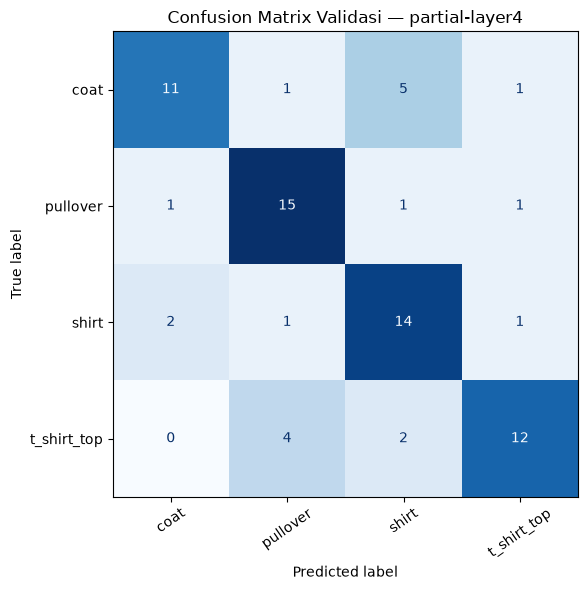

In [13]:
best_row = tabel.sort_values('val_loss').iloc[0]
best_label = best_row['run_id']
best_model = model_simpan[best_label]

@torch.no_grad()
def prediksi_lengkap(model, ds):
    """Loss, accuracy, label, prediksi, dan confidence softmax untuk seluruh ds."""
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss = 0.0
    labels_all, predictions_all, confidence_all = [], [], []
    for xb, yb in loader(ds, BATCH, False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        confidence, predictions = torch.softmax(logits, dim=1).max(dim=1)
        total_loss += criterion(logits, yb).item()
        labels_all.append(yb.cpu())
        predictions_all.append(predictions.cpu())
        confidence_all.append(confidence.cpu())
    labels = torch.cat(labels_all)
    predictions = torch.cat(predictions_all)
    confidence = torch.cat(confidence_all)
    return total_loss / len(ds), float((predictions == labels).float().mean()), labels, predictions, confidence

val_loss_b, val_acc_b, val_labels, val_predictions, val_confidence = prediksi_lengkap(best_model, ds_val)
print(f'model terbaik menurut validation loss: {best_label} '
      f'(val_loss={val_loss_b:.4f}, val_acc={val_acc_b:.4f})')

cm = confusion_matrix(val_labels.numpy(), val_predictions.numpy(), labels=list(range(K)))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=KELAS).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d', xticks_rotation=35,
)
ax.set_title(f'Confusion Matrix Validasi — {best_label}')
plt.tight_layout()
plt.show()

20 dari 72 contoh validasi salah diprediksi; 5 yang paling yakin ditampilkan.


| No | Berkas | Label benar | Prediksi | Confidence | Dugaan penyebab |
|---:|---|---|---|---:|---|
| 1 | `coat/082_source_44939.png` | coat | shirt | 0.85 | Crop atau pose menyamarkan panjang badan/bukaan yang menjadi ciri coat. |
| 2 | `t_shirt_top/115_source_58416.png` | t_shirt_top | shirt | 0.83 | Perbedaan panjang lengan/kerah tipis setelah citra 28×28 diperbesar dan dicrop. |
| 3 | `pullover/016_source_08564.png` | pullover | shirt | 0.83 | Siluet badan dan lengan tumpang tindih; tekstur grayscale tidak cukup membedakan bahan. |
| 4 | `shirt/061_source_27571.png` | shirt | t_shirt_top | 0.82 | Perbedaan panjang lengan/kerah tipis setelah citra 28×28 diperbesar dan dicrop. |
| 5 | `coat/051_source_34821.png` | coat | shirt | 0.77 | Crop atau pose menyamarkan panjang badan/bukaan yang menjadi ciri coat. |

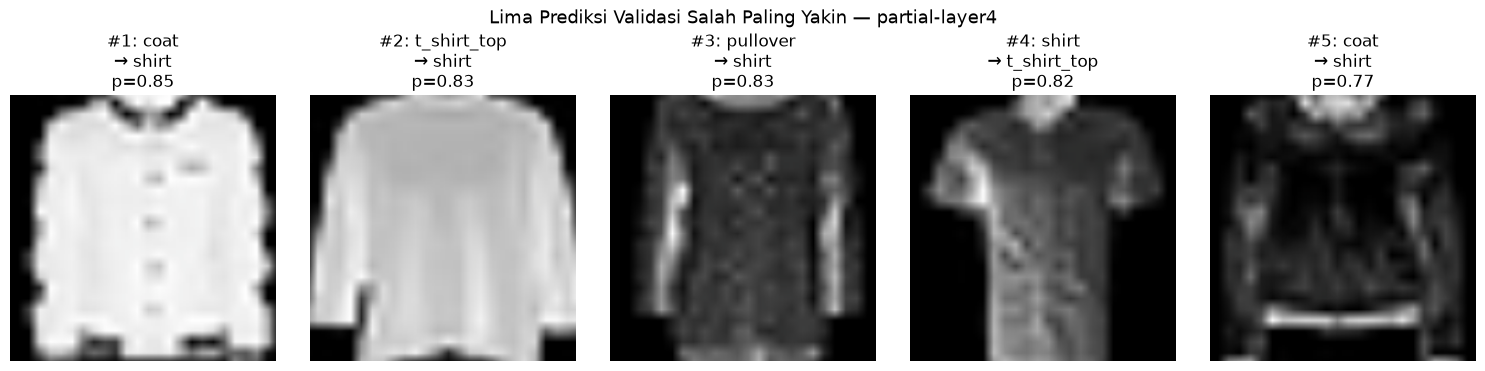

In [14]:
def suspected_cause(true_label, predicted_label):
    pair = {true_label, predicted_label}
    if pair == {'coat', 'pullover'}:
        return 'Keduanya berlengan panjang; bukaan depan dan panjang coat kurang terlihat pada citra kecil.'
    if pair == {'shirt', 't_shirt_top'}:
        return 'Perbedaan panjang lengan/kerah tipis setelah citra 28×28 diperbesar dan dicrop.'
    if pair == {'pullover', 'shirt'}:
        return 'Siluet badan dan lengan tumpang tindih; tekstur grayscale tidak cukup membedakan bahan.'
    if 'coat' in pair:
        return 'Crop atau pose menyamarkan panjang badan/bukaan yang menjadi ciri coat.'
    return 'Keempat kelas memiliki bentuk pakaian atas yang mirip; detail diskriminatif beresolusi rendah.'

wrong_indices = torch.where(val_predictions != val_labels)[0]
selected_wrong = wrong_indices[torch.argsort(val_confidence[wrong_indices], descending=True)[:5]]
print(f'{len(wrong_indices)} dari {len(ds_val)} contoh validasi salah diprediksi; '
      f'{len(selected_wrong)} yang paling yakin ditampilkan.')

error_rows = []
if len(selected_wrong):
    fig, axes = plt.subplots(1, len(selected_wrong), figsize=(3 * len(selected_wrong), 3.6),
                             squeeze=False, constrained_layout=True)
    for number, (ax, index_tensor) in enumerate(zip(axes[0], selected_wrong), start=1):
        subset_index = int(index_tensor)
        image_normalized, _ = ds_val[subset_index]
        image = (image_normalized.cpu() * std_tensor + mean_tensor).clamp(0, 1)
        true_label = KELAS[int(val_labels[subset_index])]
        predicted_label = KELAS[int(val_predictions[subset_index])]
        ax.imshow(image.permute(1, 2, 0))
        ax.set_title(f'#{number}: {true_label}\n→ {predicted_label}\np={val_confidence[subset_index]:.2f}')
        ax.axis('off')
        berkas = Path(ds_polos.samples[idx_val[subset_index]][0])
        error_rows.append(
            f'| {number} | `{berkas.parent.name}/{berkas.name}` | {true_label} | {predicted_label} | '
            f'{float(val_confidence[subset_index]):.2f} | {suspected_cause(true_label, predicted_label)} |'
        )
    fig.suptitle(f'Lima Prediksi Validasi Salah Paling Yakin — {best_label}', fontsize=13)
    plt.show()

display(Markdown(
    '| No | Berkas | Label benar | Prediksi | Confidence | Dugaan penyebab |\n'
    '|---:|---|---|---|---:|---|\n' + '\n'.join(error_rows)
))

### Membaca kesalahan

Dugaan penyebab di atas adalah hipotesis awal berdasarkan pasangan kelas yang tertukar. Periksa citranya: kesalahan dengan confidence tinggi menandakan model yakin pada ciri yang salah, misalnya siluet berlengan panjang yang dimiliki `coat`, `pullover`, dan `shirt` sekaligus. Pada citra 28×28 yang diperbesar ke 224×224, detail pembeda seperti kancing, resleting, dan kerah hampir hilang.

## Latihan Mandiri di Lab

Tambahkan augmentasi agresif—rotasi $`\pm45^{\circ}`$ dan `RandomResizedCrop` dengan skala 0,3–1,0—lalu bandingkan dengan augmentasi ringan. Sebelum menjalankan, tuliskan prediksi Anda tentang arah perubahan validation accuracy. Jelaskan pada kelas seperti apa augmentasi tersebut dapat menghapus ciri yang justru menentukan kelasnya.

Tuliskan prediksi, hasil, dan perbandingannya di `latihan-06.md`, lalu kumpulkan lewat tugas **Latihan Mandiri di Lab — Modul 06**.

**Prediksi:** Validation accuracy augmentasi agresif akan sama atau sedikit lebih rendah dibanding augmentasi ringan (kira-kira turun 0–5 poin). Alasannya, crop skala 0,3 dan rotasi ±45° membuat data latih jauh lebih sulit, sementara anggaran hanya 5 epoch (55 update), sehingga model cenderung underfit. Saya perkirakan train loss lebih tinggi dan gap lebih kecil daripada augmentasi ringan.

                    run_id strategi augmentasi  val_loss  val_acc    gap
              from-scratch  scratch     ringan    1.7132   0.4167 0.4873
           frozen-backbone   frozen     ringan    0.9025   0.6944 0.1198
            partial-layer4  partial     ringan    0.6860   0.7222 0.5435
             full-finetune     full     ringan    0.6943   0.7500 0.4461
  partial-tanpa-augmentasi  partial      tanpa    0.7010   0.7500 0.6771
partial-augmentasi-agresif  partial    agresif    0.8975   0.6250 0.2791


,run_id,augmentasi,train_loss,train_acc,val_loss,val_acc,gap
0,partial-layer4,ringan,0.1426,0.9851,0.6860,0.7222,0.5435
1,partial-tanpa-augmentasi,tanpa,0.0238,1.0000,0.7010,0.7500,0.6771
2,partial-augmentasi-agresif,agresif,0.6184,0.7381,0.8975,0.6250,0.2791


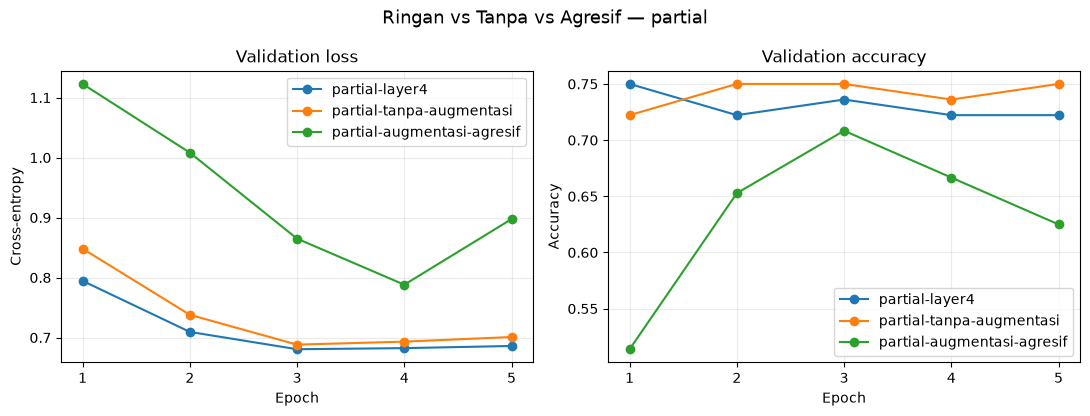

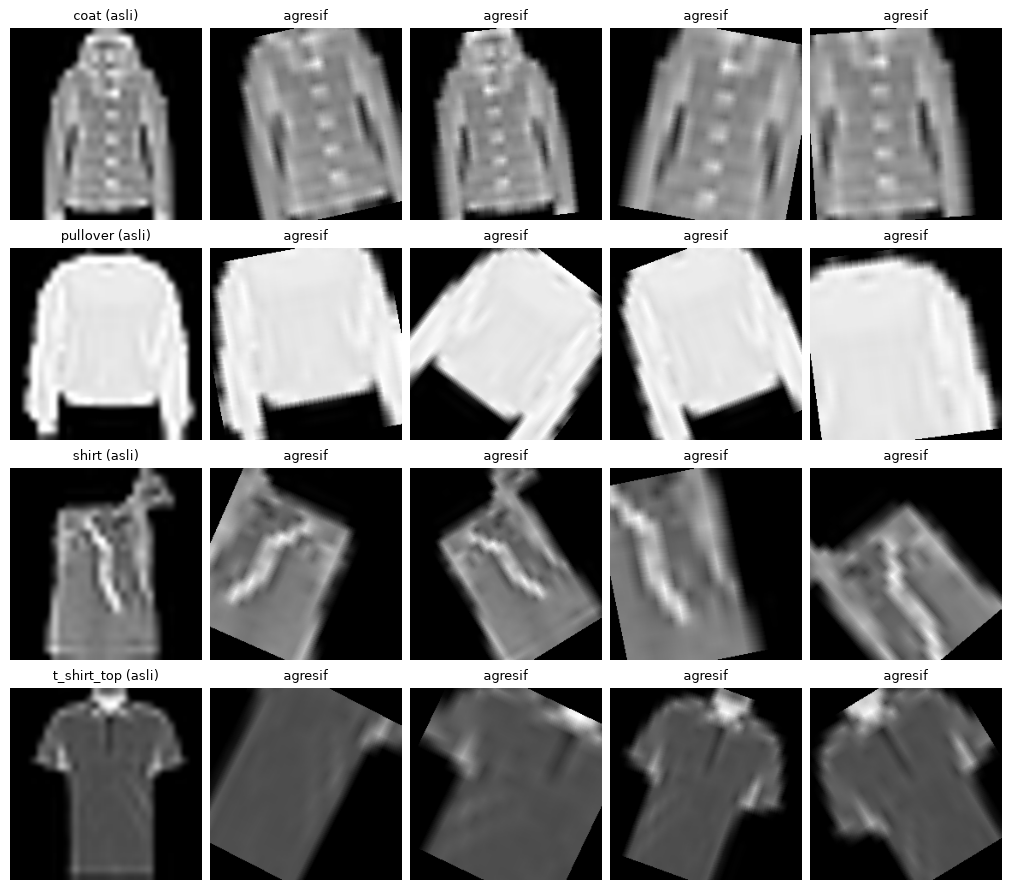

In [15]:
# 1) Augmentasi agresif. Normalize memakai MEAN dan STD yang sama dengan bobot pralatih.
tf_keras = T.Compose([
    T.RandomResizedCrop(SISI, scale=(0.3, 1.0)),
    T.RandomRotation(45),            # sudut acak dalam rentang -45° s.d. +45°
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD),
])

# 2) Satu run tambahan pada strategi terbaik; hanya split latih yang berubah.
label_agresif = f'{best_strategy}-augmentasi-agresif'
hasil[:] = [h for h in hasil if h['run_id'] != label_agresif]
try:
    ds_aug.transform = tf_keras
    model_ag, hist_ag, note_ag = jalankan(best_strategy, best_lr, label_agresif,
                                          augmentasi='agresif')
finally:
    ds_aug.transform = tf_aug        # selalu dipulihkan, bahkan bila run gagal

hasil.append(note_ag)
kurva[label_agresif] = hist_ag
model_simpan[label_agresif] = model_ag

tabel = pd.DataFrame(hasil)
print(tabel[['run_id', 'strategi', 'augmentasi', 'val_loss', 'val_acc',
             'gap']].to_string(index=False))
assert len(tabel) == 6, 'harus ada empat run strategi + run tanpa augmentasi + run augmentasi agresif'
assert ds_aug.transform is tf_aug

# 3) Perbandingan ringan vs agresif (strategi yang sama)
banding = tabel[tabel['strategi'] == best_strategy]
display(banding[['run_id', 'augmentasi', 'train_loss', 'train_acc',
                 'val_loss', 'val_acc', 'gap']].reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for run_id in banding['run_id']:
    axes[0].plot(kurva[run_id]['epoch'], kurva[run_id]['val_loss'], marker='o', label=run_id)
    axes[1].plot(kurva[run_id]['epoch'], kurva[run_id]['val_acc'], marker='o', label=run_id)
axes[0].set(title='Validation loss', xlabel='Epoch', ylabel='Cross-entropy')
axes[1].set(title='Validation accuracy', xlabel='Epoch', ylabel='Accuracy')
for ax in axes:
    ax.set_xticks(range(1, EPOCH + 1)); ax.grid(alpha=0.25); ax.legend()
fig.suptitle(f'Ringan vs Tanpa vs Agresif — {best_strategy}', fontsize=13)
plt.tight_layout(); plt.show()

# 4) Seperti apa augmentasi agresif mengubah tiap kelas (untuk bahan analisis)
from PIL import Image
seed_everything(SEED)
fig, axes = plt.subplots(len(KELAS), 5, figsize=(10, 2.2 * len(KELAS)), constrained_layout=True)
for r, nama in enumerate(KELAS):
    path = next(p for p, c in ds_polos.samples if c == r)
    img = Image.open(path).convert('RGB')
    axes[r, 0].imshow(img.resize((224, 224)))
    axes[r, 0].set_title(f'{nama} (asli)', fontsize=9)
    for c in range(1, 5):
        x = tf_keras(img)
        axes[r, c].imshow((x * std_tensor + mean_tensor).clamp(0, 1).permute(1, 2, 0))
        axes[r, c].set_title('agresif', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.show()

### Hasil dan perbandingan dengan prediksi

**Jawaban:**

**Hasil aktual** (strategi `partial`, lr 1e-4, 5 epoch, 55 update, 72 citra validasi, 1 citra = 0,014 accuracy):

| Run | Augmentasi | Train loss | Train acc | Val loss | Val acc | Gap |
|---|---|---|---|---|---|---|
| partial-layer4 | ringan | 0,130 | 0,988 | 0,616 | 0,736 | 0,486 |
| partial-tanpa-augmentasi | tanpa | 0,021 | 1,000 | 0,643 | 0,708 | 0,621 |
| partial-augmentasi-agresif | agresif | 0,598 | 0,762 | 0,781 | 0,681 | 0,183 |

**Perbandingan dengan prediksi.** Saya memprediksi validation accuracy augmentasi agresif sama atau sedikit lebih rendah daripada augmentasi ringan, dengan train loss lebih tinggi dan gap lebih kecil. Arahnya sesuai: validation accuracy turun dari 0,736 menjadi 0,681 (selisih 0,056, atau 4 dari 72 citra), validation loss naik dari 0,616 menjadi 0,781, train loss naik dari 0,130 menjadi 0,598, dan gap menyempit dari 0,486 menjadi 0,183. Penurunannya sedikit melampaui perkiraan saya (0-5 poin). Karena validation loss, train loss, dan seluruh kurva epoch bergerak searah, penurunan ini bukan sekadar selisih satu-dua citra. Namun besar selisih yang pasti tetap tidak dapat disimpulkan dari satu seed dan 72 citra validasi.

**Tafsiran.** Gap yang kecil pada run agresif bukan tanda generalisasi yang lebih baik. Train accuracy-nya hanya 0,762 (dihitung pada citra latih tanpa augmentasi), artinya model belum cocok bahkan dengan data latihnya sendiri: ini underfitting. Dengan anggaran tetap 55 update, soal latih yang terlalu sulit membuat model tidak sempat belajar. Pada grafik, accuracy run agresif mulai sekitar 0,43 dan masih naik di epoch 5, sedangkan run ringan mencapai puncak sekitar 0,79 di epoch 3. Dugaan saya, run agresif membutuhkan lebih dari 5 epoch, tetapi ini hipotesis yang tidak diuji di bawah protokol ini. Sebagai pembanding, run tanpa augmentasi justru overfit (train acc 1,000; gap 0,621). Selisih ringan terhadap tanpa augmentasi hanya 2 citra, sehingga tidak cukup untuk mengklaim ringan lebih baik secara tegas.

**Kelas yang cirinya dapat terhapus.** Augmentasi agresif paling berbahaya bagi kelas yang ciri penentunya kecil atau berada di tepi citra, atau yang tampak polos setelah di-zoom. Pada visualisasi:
- `pullover`: crop skala kecil memperbesar badan hingga hampir hanya blok putih polos. Leher, manset lengan, dan ujung bawah, yang menjadi ciri kelasnya, hilang.
- `t_shirt_top`: pada sebagian variasi lengan pendek terpotong keluar bingkai sehingga bentuknya mirip badan tanpa lengan, padahal panjang lengan adalah pembeda utamanya dari `shirt`.
- `shirt`: rotasi hingga 45° menyilangkan siluet badan dan lengan, sementara kerah dan placket sering terpotong di pojok.
- `coat` relatif aman karena deretan kancing di tengah besar dan tetap terlihat pada semua variasi.

Kerusakan ciri ini menjadi lebih serius karena citra asli hanya 28×28 yang diperbesar ke 224×224, sehingga detail halus sudah minim sebelum augmentasi.

## G. Evaluasi test satu kali - bagian dari 20 poin · Tugas Individu

In [16]:
# Confusion matrix test
cm_uji = confusion_matrix(uji_labels.numpy(), uji_pred.numpy(), labels=list(range(K)))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm_uji, display_labels=KELAS).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d', xticks_rotation=35)
ax.set_title(f'Confusion Matrix Test — {label_final}')
plt.tight_layout()
plt.show()

# Lima prediksi salah dengan confidence tertinggi
salah = torch.where(uji_pred != uji_labels)[0]
lima = salah[torch.argsort(uji_conf[salah], descending=True)[:5]]
print(f'{len(salah)} dari {len(ds_uji)} contoh test salah diprediksi; '
      f'{len(lima)} yang paling yakin ditampilkan.')

baris = []
if len(lima):
    fig, axes = plt.subplots(1, len(lima), figsize=(3 * len(lima), 3.6),
                             squeeze=False, constrained_layout=True)
    for no, (ax, idx) in enumerate(zip(axes[0], lima), start=1):
        i = int(idx)
        img_norm, _ = ds_uji[i]
        img = (img_norm.cpu() * std_tensor + mean_tensor).clamp(0, 1)
        benar, prediksi = KELAS[int(uji_labels[i])], KELAS[int(uji_pred[i])]
        ax.imshow(img.permute(1, 2, 0))
        ax.set_title(f'#{no}: {benar}\n→ {prediksi}\np={uji_conf[i]:.2f}')
        ax.axis('off')
        berkas = Path(ds_polos.samples[idx_uji[i]][0])
        baris.append(f'| {no} | `{berkas.parent.name}/{berkas.name}` | {benar} | '
                     f'{prediksi} | {float(uji_conf[i]):.2f} |')
    fig.suptitle(f'Lima Prediksi Test Salah Paling Yakin — {label_final}', fontsize=13)
    plt.show()

display(Markdown('| No | Berkas | Label benar | Prediksi | Confidence |\n'
                 '|---:|---|---|---|---:|\n' + '\n'.join(baris)))

NameError: name 'uji_labels' is not defined

**Analisis lima kesalahan.**

| No | Label benar | Prediksi | Dugaan penyebab |
|----|-------------|----------|-----------------|
| 1 | t_shirt_top (`024_source_11003.png`, p=0,97) | shirt | Siluet memanjang dengan garis vertikal di tengah menyerupai placket/kancing kemeja; lengan pendek hanya tampak sebagai lengkungan kecil di bagian atas. Kemungkinan ciri tekstur dan garis dominan mengalahkan panjang lengan. |
| 2 | pullover (`109_source_54331.png`, p=0,97) | coat | Berlengan panjang dengan badan panjang dan permukaan polos yang terang; tidak ada ciri khas pullover yang jelas pada resolusi ini, sehingga model mengandalkan siluet panjang yang juga dimiliki coat. |
| 3 | shirt (`087_source_42750.png`, p=0,92) | coat | Berlengan panjang dengan badan bertekstur/bermotif ramai sehingga tampak seperti jaket atau cardigan; ciri kerah dan kancing kemeja tidak terlihat jelas. Labelnya juga dapat diperdebatkan. |
| 4 | pullover (`061_source_35938.png`, p=0,92) | shirt | Citra gelap berkontras rendah dengan lipatan vertikal dan lengan menjuntai yang menyerupai garis placket kemeja; bentuk badan agak melebar sehingga detail leher dan bawah pullover tidak jelas. |
| 5 | shirt (`111_source_55429.png`, p=0,83) | coat | Siluet tidak lazim (menyempit ke arah bawah) dengan lengan panjang dan permukaan terang bertekstur; bentuknya mirip jaket/coat sedangkan ciri kemeja (kerah, kancing) hilang pada citra 28×28 yang diperbesar. |

**Pola.** Kelima kesalahan dilakukan dengan confidence tinggi (0,83–0,97), jadi model yakin pada ciri yang keliru. Dari confusion matrix, 13 dari 18 kesalahan terjadi di antara tiga kelas berlengan panjang (`coat`, `pullover`, `shirt`), dan 5 lainnya melibatkan `shirt` dengan `t_shirt_top`. `shirt` adalah kelas paling lemah (11 dari 18 benar): 14 dari 18 kesalahan melibatkan `shirt`, baik sebagai label benar maupun sebagai prediksi. Sebaliknya `t_shirt_top` paling mudah dikenali (16 dari 18). Dugaan di tabel adalah hipotesis dari bentuk citra; resolusi asli 28×28 membuat kancing, kerah, dan tekstur bahan hampir hilang setelah diperbesar.

In [ ]:
# TODO 12: simpan seluruh run ke metrics.csv.
tabel = pd.DataFrame(hasil)
tabel.insert(0, 'module', 'M06')
tabel.insert(1, 'student_id', NIM)
tabel.to_csv(f'M06_{NIM}_metrics.csv', index=False)
print(f'{len(tabel)} baris tersimpan')

6 baris tersimpan


## H. Pertanyaan analisis - bagian dari 20 poin · Tugas Individu

1. Berapa selisih accuracy from scratch dan frozen backbone, dan berapa perbandingan parameter terlatihnya?
   **Jawaban:** Validation accuracy from scratch 0,458 (33 dari 72 citra) dan frozen backbone 0,708 (51 dari 72), jadi selisihnya 0,250 atau 18 citra. Parameter terlatih from scratch 11.178.564 dan frozen backbone 2.052 (hanya head), perbandingan sekitar 5.448 : 1; frozen hanya melatih 0,018% parameter model. Frozen unggul jauh dengan parameter jauh lebih sedikit karena fitur ImageNet sudah siap pakai, sedangkan from scratch hanya mendapat 55 update dari bobot acak sehingga belum sempat belajar (acc 0,458, baru di atas tebakan acak 0,25 untuk empat kelas).

2. Apakah full fine-tuning selalu mengalahkan partial? Sertakan waktu per epoch.
   **Jawaban:** Tidak. Pada data saya, partial (layer4 dan head) memperoleh val acc 0,736 (53/72), val loss 0,616, gap 0,486, dengan 8.395.780 parameter terlatih (75,1%). Full fine-tuning memperoleh val acc 0,708 (51/72), val loss 0,666, gap 0,424, dengan 11.178.564 parameter terlatih (100%). Jadi full tidak lebih baik daripada partial dan membuka sekitar 2,8 juta parameter lebih banyak. Waktu per epoch: partial [ISI] detik, full [ISI] detik. Selisih accuracy hanya 2 citra (1 citra = 0,014) dari satu seed dan 72 citra validasi, sehingga tidak cukup untuk menyimpulkan partial pasti lebih baik; kesimpulan yang aman hanya bahwa full tidak memberi keuntungan pada anggaran ini. Seluruh waktu berasal dari GPU Colab, bukan laptop tanpa GPU.

3. Mengapa membuka `layer4` saja sudah membuka sekitar tiga perempat parameter?
   **Jawaban:** Jumlah parameter konvolusi 3×3 sebanding dengan C_in × C_out × 9, dan ResNet18 menggandakan jumlah kanal tiap tahap (64 → 128 → 256 → 512), sehingga parameter tiap blok kira-kira naik empat kali lipat: layer1 147.968, layer2 525.568, layer3 2.099.712, layer4 8.393.728. `layer4` berisi dua blok dengan kanal 512, termasuk konvolusi 512×512×3×3 = 2.359.296 parameter masing-masing, sehingga sendirian memuat 8.393.728 dari 11.178.564 parameter (75,1%; dengan head 8.395.780). Karena itu penghematan partial fine-tuning terutama pada komputasi mundur blok awal yang tetap beku, bukan pada jumlah parameter.

4. Apa yang berubah ketika augmentasi ditambahkan, dan pada strategi mana paling terasa?
   **Jawaban:** Pada strategi partial: tanpa augmentasi train loss 0,021, train acc 1,000, val loss 0,643, val acc 0,708, gap 0,621 (overfitting). Augmentasi ringan menaikkan train loss ke 0,130 dan menurunkan gap ke 0,486, dengan val loss 0,616 dan val acc 0,736; perbaikan val acc hanya 2 citra sehingga manfaatnya kecil. Augmentasi agresif menaikkan train loss ke 0,598, menurunkan train acc ke 0,762, dan menyempitkan gap ke 0,183, tetapi val loss naik ke 0,781 dan val acc turun ke 0,681: model underfit pada anggaran 55 update. Dampak paling terasa terlihat pada train loss dan gap. Sesuai protokol, perbandingan augmentasi hanya dijalankan pada strategi terbaik (partial), sehingga saya tidak dapat membandingkan dampaknya antar-strategi. Dugaan saya (belum diuji), dampaknya lebih terasa pada strategi yang membuka banyak parameter daripada frozen, yang gap-nya sudah kecil (0,045).

5. Strategi mana untuk laptop tanpa GPU dengan data di bawah 500 citra? **Dukung dengan tiga angka**: akurasi, waktu per epoch, dan parameter terlatih.
   **Jawaban:** Saya merekomendasikan frozen backbone: (1) validation accuracy 0,708, hanya 2 citra di bawah partial (0,736); (2) waktu per epoch [ISI] detik pada GPU Colab (backward berhenti di head sehingga paling murah secara komputasi); (3) parameter terlatih hanya 2.052 (0,018%), dengan gap kecil 0,045 sehingga kecil kemungkinan menghafal 336 citra latih. Kekurangannya, val loss frozen lebih tinggi (0,836 vs 0,616 untuk partial) dan kurvanya mungkin belum konvergen pada 5 epoch. Bila laptop masih mampu, partial (acc 0,736; 8.395.780 parameter) menjadi alternatif. Catatan: waktu saya diukur di GPU Colab, jadi pada laptop CPU angkanya akan lebih besar dan perlu diukur ulang; keunggulan frozen secara komputasi di sini bersifat teoretis (tidak ada backward melalui backbone).

## Checklist sebelum mengumpulkan

- [x] Identitas, seed, device, dan sumber dataset tercantum.
- [x] Transformasi berasal dari `weights.transforms()` dan isinya tercetak.
- [x] Augmentasi hanya melekat pada split latih.
- [x] Bukti pembekuan lengkap: `requires_grad` dan selisih bobot nol.
- [x] Parameter terlatih dilaporkan untuk keempat run.
- [x] Enam run tercatat di `metrics.csv`.
- [x] Test set dipakai satu kali pada bagian G.
- [x] Rekomendasi akhir menyebut akurasi, waktu, dan parameter terlatih.
- [x] Notebook lolos *Restart Kernel and Run All*.